# Generalised Railway Platform Allocation — Encoding Benchmark V7

## Purpose

V7 is a **generalised synthetic benchmark**. It is not tied to Jaipur or any specific station. It compares three QUBO representations of the same railway platform-allocation problem:

1. **One-hot encoding:** one binary variable per eligible train-platform pair.
2. **Binary encoding with indicator/AND auxiliaries:** binary platform code bits plus QUBO variables that identify eligible platform codes.
3. **Domain-wall encoding:** `P-1` ordered state bits per train, with platform indicators represented as differences of adjacent bits.

The objective and operational constraints remain the same across the encodings:

- exactly one eligible platform per train;
- no two overlapping trains may occupy the same platform;
- longer trains may use only the designated long-train-capable platforms;
- minimise the number of trains moved from their nominal platform.

All train-level schedules, nominal assignments, coach counts and conflicts in this notebook are synthetic. They are generated to span low, medium and high temporal congestion. No station-specific data are used.

## Main research question

**Does the choice of QUBO encoding materially change feasibility, solution quality, energy-landscape accessibility, runtime and model size for SA and SQA?**

OpenJij SQA is a classical simulation of quantum annealing dynamics. It is not a run on quantum hardware, and this notebook makes no quantum-advantage assumption.

## How to use this notebook

- Start with `STUDY_MODE = "PILOT"` and run all cells.
- Review the encoding validation and pilot results before scaling up.
- Change `STUDY_MODE` to `"FULL"` only after the pilot completes successfully. The full study is substantially more expensive.
- Keep the exported CSV files with the executed notebook.

### Study sizes

| Mode | Train counts | Difficulty levels | Seeds | Datasets |
|---|---|---|---|---:|
| Pilot | 8, 12, 16 | Low, medium, high | 11, 22, 33 | 27 |
| Full | 8, 12, 16, 20, 24, 32 | Low, medium, high | 11, 22, 33 | 54 |

The pilot uses two sampler repeats, 50 reads and 500 sweeps. The full study uses five repeats, 100 reads and 1,000 sweeps.

## 0. Environment setup

Run this cell only if the required packages are missing. OpenJij 0.12.x is the environment used in the preceding experiments.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and hardware information

In [2]:
import sys, platform, time, math, json, itertools, random, importlib.metadata, warnings
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)

Python: 3.12.12
OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2


## 2. Experiment controls

`PILOT` is deliberately the default. The full study expands from 27 to 54 datasets and raises the repeat/read/sweep budget. Do not switch to `FULL` until the pilot's correctness checks pass.

In [3]:
STUDY_MODE = "PILOT"  # Change to "FULL" only after reviewing the pilot.
RUN_EXPERIMENT = True
RUN_EXHAUSTIVE_ENCODING_TEST = True
RUN_LANDSCAPE_DIAGNOSTICS = True

N_PLATFORMS = 6
LONG_PLATFORM_COUNT = 4
LONG_TRAIN_COACH_THRESHOLD = 24
CLEARANCE_MIN = 5  # Declared modelling assumption; applied consistently to all encodings.

DIFFICULTY_CONFIG = {
    "low":    {"horizon_min": 600, "dwell_min": 12, "dwell_max": 20, "delay_max_min": 3},
    "medium": {"horizon_min": 480, "dwell_min": 15, "dwell_max": 25, "delay_max_min": 8},
    "high":   {"horizon_min": 360, "dwell_min": 18, "dwell_max": 30, "delay_max_min": 15},
}

if STUDY_MODE.upper() == "PILOT":
    TRAIN_COUNTS = [8, 12, 16]
    DATASET_SEEDS = [11, 22, 33]
    SOLVER_REPEATS = 2
    NUM_READS = 50
    NUM_SWEEPS = 500
    EXACT_TIME_LIMIT_S = 2.0
elif STUDY_MODE.upper() == "FULL":
    TRAIN_COUNTS = [8, 12, 16, 20, 24, 32]
    DATASET_SEEDS = [11, 22, 33]
    SOLVER_REPEATS = 5
    NUM_READS = 100
    NUM_SWEEPS = 1000
    EXACT_TIME_LIMIT_S = 5.0
else:
    raise ValueError("STUDY_MODE must be PILOT or FULL")

DIFFICULTIES = ["low", "medium", "high"]
ENCODINGS = ["one_hot", "binary_aux", "domain_wall"]
ALGORITHMS = ["SA", "SQA"]
GREEDY_RESTARTS = 30
SEED_BASE = 770000

EXPECTED_DATASETS = len(TRAIN_COUNTS) * len(DIFFICULTIES) * len(DATASET_SEEDS)
EXPECTED_SAMPLER_CALLS = EXPECTED_DATASETS * len(ENCODINGS) * len(ALGORITHMS) * SOLVER_REPEATS
print("Study mode:", STUDY_MODE)
print("Expected datasets:", EXPECTED_DATASETS)
print("Expected SA/SQA sampler calls:", EXPECTED_SAMPLER_CALLS)
print("Reads/sweeps per call:", NUM_READS, NUM_SWEEPS)
print("Estimated total reads:", EXPECTED_SAMPLER_CALLS * NUM_READS)

Study mode: PILOT
Expected datasets: 27
Expected SA/SQA sampler calls: 324
Reads/sweeps per call: 50 500
Estimated total reads: 16200


## 3. Generalised synthetic railway-instance generator

The generator varies temporal congestion using the horizon, dwell-time range and delay range. Nominal platform assignments are chosen from each train's eligible platforms. Actual conflict edges are computed from the delayed occupancy intervals plus the common clearance assumption.

The three difficulty labels are experimental scenario settings, not claims about real railway systems. We report the **observed** conflict density for each instance rather than assuming that a label implies a particular density.

In [4]:
def generate_instance(n_trains: int, difficulty: str, seed: int,
                      n_platforms: int = N_PLATFORMS,
                      long_platform_count: int = LONG_PLATFORM_COUNT,
                      clearance_min: int = CLEARANCE_MIN) -> pd.DataFrame:
    if difficulty not in DIFFICULTY_CONFIG:
        raise ValueError(f"Unknown difficulty: {difficulty}")
    if n_trains < 1 or n_platforms < 2:
        raise ValueError("Need at least one train and two platforms")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("Invalid long-platform count")
    cfg = DIFFICULTY_CONFIG[difficulty]
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(n_trains):
        coaches = int(rng.integers(10, 31))
        is_long = coaches >= LONG_TRAIN_COACH_THRESHOLD
        eligible = list(range(long_platform_count)) if is_long else list(range(n_platforms))
        nominal = int(rng.choice(eligible))
        dwell = int(rng.integers(cfg["dwell_min"], cfg["dwell_max"] + 1))
        latest = max(0, cfg["horizon_min"] - dwell)
        scheduled_arrival = int(rng.integers(0, latest + 1))
        delay = int(rng.integers(0, cfg["delay_max_min"] + 1))
        actual_arrival = scheduled_arrival + delay
        actual_departure = actual_arrival + dwell
        rows.append({
            "train_index": i,
            "train_id": f"T{i+1:04d}",
            "coaches": coaches,
            "is_long": bool(is_long),
            "nominal_platform": nominal,
            "eligible_platforms": eligible,
            "scheduled_arrival_min": scheduled_arrival,
            "scheduled_departure_min": scheduled_arrival + dwell,
            "delay_min": delay,
            "actual_arrival_min": actual_arrival,
            "actual_departure_min": actual_departure,
            "dwell_min": dwell,
            "difficulty": difficulty,
            "seed": int(seed),
        })
    return pd.DataFrame(rows)


def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int, int]]:
    edges = []
    n = len(df)
    starts = df["actual_arrival_min"].astype(int).tolist()
    ends = (df["actual_departure_min"].astype(int) + int(clearance_min)).tolist()
    for i in range(n):
        for j in range(i + 1, n):
            if starts[i] < ends[j] and starts[j] < ends[i]:
                edges.append((i, j))
    return edges


def assignment_cost(assignment: Dict[int, int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment: Optional[Dict[int, int]], df: pd.DataFrame,
                        conflicts: List[Tuple[int, int]]) -> Tuple[bool, List[str]]:
    if assignment is None or set(assignment) != set(range(len(df))):
        return False, ["missing_train_assignment"]
    violations = []
    for i, p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i, j in conflicts:
        if assignment.get(i) == assignment.get(j):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations) == 0, violations


def conflict_density(n_trains: int, conflicts: List[Tuple[int, int]]) -> float:
    possible = n_trains * (n_trains - 1) / 2
    return len(conflicts) / possible if possible else 0.0

print("Generator and validator defined.")

Generator and validator defined.


## 4. Classical Greedy baseline and Exact Search

Greedy uses a degree/saturation-informed train order and randomized restarts. Exact Search is a branch-and-bound solver seeded with the best feasible Greedy assignment. A timeout is never reported as infeasibility or as a proven optimum.

In [5]:
def greedy_assignment(df: pd.DataFrame, conflicts: List[Tuple[int, int]],
                      seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int, int]]:
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    best, best_cost = None, float("inf")
    master_rng = np.random.default_rng(seed)
    for _ in range(restarts):
        rng = np.random.default_rng(int(master_rng.integers(0, 2**31 - 1)))
        assigned = {}
        loads = {p: 0 for p in range(N_PLATFORMS)}
        while len(assigned) < n:
            candidates = []
            for i in range(n):
                if i in assigned:
                    continue
                used = {assigned[j] for j in neighbours[i] if j in assigned}
                available = [int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
                saturation = len(used)
                candidates.append((len(available), -saturation, -len(neighbours[i]), float(rng.random()), i, available))
            # Fail this restart if any unassigned train has no available platform.
            if any(len(item[5]) == 0 for item in candidates):
                break
            # MRV first, then higher saturation/degree. Random value breaks exact ties.
            _, _, _, _, i, available = min(candidates, key=lambda z: (z[0], z[1], z[2], z[3]))
            nominal = int(df.iloc[i].nominal_platform)
            # Preserve nominal platform whenever possible; otherwise spread load.
            available.sort(key=lambda p: (p != nominal, loads[p], float(rng.random())))
            p = available[0]
            assigned[i] = p
            loads[p] += 1
        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost:
                    best, best_cost = assigned.copy(), cost
    return best


def exact_branch_and_bound(df: pd.DataFrame, conflicts: List[Tuple[int, int]],
                           incumbent: Optional[Dict[int, int]] = None,
                           time_limit_s: float = EXACT_TIME_LIMIT_S) -> Dict[str, Any]:
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    best_assignment, best_cost = None, float("inf")
    if incumbent is not None:
        ok, _ = validate_assignment(incumbent, df, conflicts)
        if ok:
            best_assignment = dict(incumbent)
            best_cost = assignment_cost(best_assignment, df)
    start = time.perf_counter()
    nodes = 0
    timed_out = False

    def recurse(assigned: Dict[int, int], current_cost: int):
        nonlocal best_assignment, best_cost, nodes, timed_out
        nodes += 1
        if time.perf_counter() - start >= time_limit_s:
            timed_out = True
            return
        if len(assigned) == n:
            if current_cost < best_cost:
                best_cost, best_assignment = current_cost, dict(assigned)
            return
        domains = {}
        for i in range(n):
            if i in assigned:
                continue
            used = {assigned[j] for j in neighbours[i] if j in assigned}
            domains[i] = [int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not domains[i]:
                return
        lower_bound = current_cost
        for i, options in domains.items():
            if int(df.iloc[i].nominal_platform) not in options:
                lower_bound += 1
        if lower_bound >= best_cost:
            return
        i = min(domains, key=lambda k: (len(domains[k]), -len(neighbours[k]), k))
        nominal = int(df.iloc[i].nominal_platform)
        options = sorted(domains[i], key=lambda p: (p != nominal, p))
        for p in options:
            new_cost = current_cost + int(p != nominal)
            if new_cost >= best_cost:
                continue
            assigned[i] = p
            recurse(assigned, new_cost)
            del assigned[i]
            if timed_out:
                return

    recurse({}, 0)
    elapsed = time.perf_counter() - start
    if timed_out:
        status = "TIMEOUT"
    elif best_assignment is None:
        status = "INFEASIBLE"
    else:
        status = "OPTIMAL"
    return {"status": status, "assignment": best_assignment, "cost": best_cost if best_assignment is not None else None,
            "runtime_s": elapsed, "nodes": nodes, "incumbent_source": "greedy" if incumbent is not None and best_assignment == incumbent else "search_or_greedy"}

print("Greedy and exact solvers defined.")

Greedy and exact solvers defined.


## 5. QUBO polynomial utilities

The builders use a small Boolean-polynomial utility. Binary variables satisfy `x*x = x`, so expressions are reduced to constant, linear and quadratic terms. Every generated QUBO is checked for degree at most two.

In [6]:
# A Boolean polynomial maps a sorted tuple of variable names to a coefficient.
# The empty tuple represents a constant.
def poly_add(a, b, scale=1.0):
    out = dict(a)
    for key, value in b.items():
        out[key] = out.get(key, 0.0) + scale * value
    return {k: v for k, v in out.items() if abs(v) > 1e-12}


def poly_scale(a, scale):
    return {k: v * scale for k, v in a.items() if abs(v * scale) > 1e-12}


def poly_mul(a, b):
    out = {}
    for ka, va in a.items():
        for kb, vb in b.items():
            key = tuple(sorted(set(ka).union(kb)))  # x^2 = x for binary variables
            if len(key) > 2:
                raise ValueError(f"Polynomial degree exceeded 2: {key}")
            out[key] = out.get(key, 0.0) + va * vb
    return {k: v for k, v in out.items() if abs(v) > 1e-12}


def pvar(name):
    return {(str(name),): 1.0}


def paffine(constant=0.0, coefficients=None):
    out = {}
    if abs(constant) > 1e-12:
        out[()] = float(constant)
    for name, coef in (coefficients or {}).items():
        if abs(coef) > 1e-12:
            out[(str(name),)] = out.get((str(name),), 0.0) + float(coef)
    return {k: v for k, v in out.items() if abs(v) > 1e-12}


def add_and_penalty(poly, a_expr, b_expr, z_name, weight):
    # Nonnegative QUBO penalty: ab - 2az - 2bz + 3z; zero iff z = a AND b.
    z = pvar(z_name)
    term = poly_mul(a_expr, b_expr)
    term = poly_add(term, poly_mul(a_expr, z), -2.0)
    term = poly_add(term, poly_mul(b_expr, z), -2.0)
    term = poly_add(term, z, 3.0)
    return poly_add(poly, term, float(weight))


def add_equality_penalty(poly, a_expr, b_expr, weight):
    # For binary-valued affine expressions, (a-b)^2 is quadratic after x^2=x reduction.
    diff = poly_add(a_expr, b_expr, -1.0)
    square = poly_mul(diff, diff)
    return poly_add(poly, square, float(weight))


def add_onehot_penalty(poly, variable_names, weight):
    # weight * (sum(x)-1)^2 = weight * (1 - sum(x) + 2 sum_{i<j} x_i x_j)
    poly = poly_add(poly, {(): 1.0}, float(weight))
    for name in variable_names:
        poly = poly_add(poly, pvar(name), -float(weight))
    for a, b in itertools.combinations(variable_names, 2):
        poly = poly_add(poly, poly_mul(pvar(a), pvar(b)), 2.0 * float(weight))
    return poly


def poly_to_qubo(poly):
    offset = float(poly.get((), 0.0))
    Q = {}
    for key, value in poly.items():
        if not key:
            continue
        if len(key) == 1:
            qkey = (key[0], key[0])
        elif len(key) == 2:
            qkey = tuple(sorted(key))
        else:
            raise ValueError(f"Non-QUBO term encountered: {key}")
        Q[qkey] = Q.get(qkey, 0.0) + float(value)
    Q = {k: v for k, v in Q.items() if abs(v) > 1e-12}
    return Q, offset


def evaluate_qubo(Q, offset, sample):
    total = float(offset)
    for (a, b), coefficient in Q.items():
        total += float(coefficient) * int(sample.get(a, 0)) * int(sample.get(b, 0))
    return float(total)


def qubo_metrics(Q, variables, offset):
    nvar = len(variables)
    interactions = sum(1 for a, b in Q if a != b)
    coeffs = [abs(v) for v in Q.values() if abs(v) > 1e-12]
    possible = nvar * (nvar - 1) / 2
    return {"n_variables": nvar, "n_linear_terms": sum(1 for a,b in Q if a==b),
            "n_quadratic_interactions": interactions,
            "interaction_density": interactions / possible if possible else 0.0,
            "max_abs_coefficient": max(coeffs) if coeffs else 0.0,
            "min_abs_nonzero_coefficient": min(coeffs) if coeffs else 0.0,
            "offset": float(offset)}

print("Polynomial utilities defined.")

Polynomial utilities defined.


## 6. Three QUBO encodings

### Penalty logic

The reassignment cost is at most `N`. For one-hot and binary-auxiliary models, an invalid assignment/link state incurs a penalty of `N+1`, which is greater than any feasible reassignment cost when a feasible schedule exists.

The domain-wall formulation uses `P-1` state bits. Platform indicators are represented by differences of adjacent bits. Its non-wall polynomial can have signed coefficients on invalid bit strings, so the notebook computes a conservative wall-penalty bound from the sum of absolute non-wall coefficients. This avoids silently assuming that an arbitrary small domain-wall penalty is sufficient.

Large penalty bounds can worsen annealing numerics; their magnitude and coefficient spread are therefore part of the results.

In [7]:
def build_one_hot(df, conflicts, n_platforms=N_PLATFORMS):
    n = len(df)
    lam = float(n + 1)
    poly = {}
    y = {}
    variables = []
    for i in range(n):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        names = []
        for p in eligible:
            name = f"oh_{i}_{p}"
            y[(i,p)] = name; variables.append(name); names.append(name)
            if p != int(df.iloc[i].nominal_platform):
                poly = poly_add(poly, pvar(name), 1.0)
        poly = add_onehot_penalty(poly, names, lam)
    for i, j in conflicts:
        common = sorted(set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms)))
        for p in common:
            poly = poly_add(poly, poly_mul(pvar(y[(i,p)]), pvar(y[(j,p)])), lam)
    Q, offset = poly_to_qubo(poly)
    return {"encoding":"one_hot", "Q":Q, "offset":offset, "variables":variables,
            "y":y, "lambda_assign":lam, "lambda_conflict":lam,
            "penalties":{"assignment":lam,"conflict":lam}}


def build_binary_aux(df, conflicts, n_platforms=N_PLATFORMS):
    n = len(df)
    k = int(math.ceil(math.log2(n_platforms)))
    lam = float(n + 1)
    poly = {}
    bits, y, chains = {}, {}, {}
    variables = []
    for i in range(n):
        bit_names = [f"bin_{i}_b{kidx}" for kidx in range(k)]
        bits[i] = bit_names; variables.extend(bit_names)
        y_names = []
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        for p in eligible:
            code_lits = []
            for kidx, bitname in enumerate(bit_names):
                if (p >> kidx) & 1:
                    code_lits.append(pvar(bitname))
                else:
                    code_lits.append(paffine(1.0, {bitname:-1.0}))
            chain = []
            current = code_lits[0]
            for stage in range(1, k):
                out_name = f"bin_{i}_p{p}_and{stage}" if stage < k-1 else f"bin_{i}_y{p}"
                variables.append(out_name); chain.append(out_name)
                poly = add_and_penalty(poly, current, code_lits[stage], out_name, lam)
                current = pvar(out_name)
            if k == 1:
                out_name = f"bin_{i}_y{p}"
                variables.append(out_name); chain.append(out_name)
                # y = literal, expressed as a squared equality.
                poly = add_equality_penalty(poly, pvar(out_name), code_lits[0], lam)
            y[(i,p)] = chain[-1]
            chains[(i,p)] = chain
            y_names.append(chain[-1])
            if p != int(df.iloc[i].nominal_platform):
                poly = poly_add(poly, pvar(chain[-1]), 1.0)
        poly = add_onehot_penalty(poly, y_names, lam)
    for i, j in conflicts:
        common = sorted(set(map(int, df.iloc[i].eligible_platforms)).intersection(map(int, df.iloc[j].eligible_platforms)))
        for p in common:
            poly = poly_add(poly, poly_mul(pvar(y[(i,p)]), pvar(y[(j,p)])), lam)
    Q, offset = poly_to_qubo(poly)
    return {"encoding":"binary_aux", "Q":Q, "offset":offset, "variables":variables,
            "bits":bits, "y":y, "chains":chains,
            "lambda_assign":lam, "lambda_conflict":lam, "lambda_link":lam,
            "penalties":{"assignment":lam,"conflict":lam,"AND/equality_link":lam}}


def domain_wall_indicator_expr(i, p, n_platforms, bit_names):
    # Valid domain-wall strings are 111...1100...00; platform p is the boundary location.
    if p == 0:
        return paffine(1.0, {bit_names[0]:-1.0})
    if p == n_platforms - 1:
        return pvar(bit_names[-1])
    return paffine(0.0, {bit_names[p-1]:1.0, bit_names[p]:-1.0})


def build_domain_wall(df, conflicts, n_platforms=N_PLATFORMS):
    n = len(df)
    lam_conflict = float(n + 1)
    lam_elig = float(n + 1)
    poly_nonwall = {}
    bits = {}
    variables = []
    indicators = {}
    for i in range(n):
        bit_names = [f"dw_{i}_d{k}" for k in range(n_platforms - 1)]
        bits[i] = bit_names; variables.extend(bit_names)
        for p in range(n_platforms):
            y_expr = domain_wall_indicator_expr(i, p, n_platforms, bit_names)
            indicators[(i,p)] = y_expr
            if p != int(df.iloc[i].nominal_platform):
                poly_nonwall = poly_add(poly_nonwall, y_expr, 1.0)
            if p not in [int(x) for x in df.iloc[i].eligible_platforms]:
                poly_nonwall = poly_add(poly_nonwall, y_expr, lam_elig)
    for i, j in conflicts:
        for p in range(n_platforms):
            poly_nonwall = poly_add(poly_nonwall,
                                    poly_mul(indicators[(i,p)], indicators[(j,p)]),
                                    lam_conflict)
    # Conservative lower-bound guard: any invalid 0->1 transition costs lambda_wall;
    # all non-wall terms together are bounded below by -sum(abs(coefficients)).
    coefficient_l1 = sum(abs(v) for v in poly_nonwall.values())
    lam_wall = float(coefficient_l1 + n + 1)
    poly = dict(poly_nonwall)
    for i in range(n):
        bit_names = bits[i]
        for kidx in range(n_platforms - 2):
            # Forbidden 0->1 transition: d[k+1] * (1-d[k]).
            transition = poly_add(pvar(bit_names[kidx+1]),
                                  poly_mul(pvar(bit_names[kidx+1]), pvar(bit_names[kidx])), -1.0)
            poly = poly_add(poly, transition, lam_wall)
    Q, offset = poly_to_qubo(poly)
    return {"encoding":"domain_wall", "Q":Q, "offset":offset, "variables":variables,
            "bits":bits, "indicators":indicators,
            "lambda_conflict":lam_conflict,"lambda_eligibility":lam_elig,"lambda_wall":lam_wall,
            "nonwall_l1_bound":coefficient_l1,
            "penalties":{"conflict":lam_conflict,"eligibility":lam_elig,"domain_wall":lam_wall}}


def build_encoding(encoding, df, conflicts, n_platforms=N_PLATFORMS):
    if encoding == "one_hot": return build_one_hot(df, conflicts, n_platforms)
    if encoding == "binary_aux": return build_binary_aux(df, conflicts, n_platforms)
    if encoding == "domain_wall": return build_domain_wall(df, conflicts, n_platforms)
    raise ValueError(f"Unknown encoding: {encoding}")

print("All three QUBO builders defined.")

All three QUBO builders defined.


## 7. Assignment encoding and raw-sample decoder

A sampler sample counts as **raw feasible** only when its encoded state is internally consistent, selects exactly one eligible platform per train, and satisfies every train-conflict edge. No classical repair step is applied to raw samples. This prevents post-processing from being misreported as annealer feasibility.

In [8]:
def encode_assignment(assignment, df, model, n_platforms=N_PLATFORMS):
    enc = model["encoding"]
    sample = {v:0 for v in model["variables"]}
    if enc == "one_hot":
        for i, p in assignment.items(): sample[model["y"][(i,int(p))]] = 1
    elif enc == "binary_aux":
        for i, p in assignment.items():
            for kidx, name in enumerate(model["bits"][i]): sample[name] = (int(p) >> kidx) & 1
            for q in [int(x) for x in df.iloc[i].eligible_platforms]:
                chain = model["chains"][(i,q)]
                literals = [((int(q) >> kidx) & 1) == 1 for kidx in range(len(model["bits"][i]))]
                bit_values = [sample[name] for name in model["bits"][i]]
                current = bit_values[0] if literals[0] else 1-bit_values[0]
                for stage in range(1, len(bit_values)):
                    lit = bit_values[stage] if literals[stage] else 1-bit_values[stage]
                    current = int(current and lit)
                    sample[chain[stage-1]] = current
    elif enc == "domain_wall":
        for i, p in assignment.items():
            for kidx, name in enumerate(model["bits"][i]): sample[name] = int(kidx < int(p))
    else:
        raise ValueError(enc)
    return sample


def decode_raw_sample(sample, df, conflicts, model, n_platforms=N_PLATFORMS):
    enc = model["encoding"]
    assignment = {}
    for i in range(len(df)):
        eligible = [int(p) for p in df.iloc[i].eligible_platforms]
        if enc == "one_hot":
            selected = [p for p in eligible if int(sample.get(model["y"][(i,p)],0)) == 1]
            if len(selected) != 1: return False, None, "one_hot_cardinality"
            assignment[i] = selected[0]
        elif enc == "binary_aux":
            bit_values = [int(sample.get(name,0)) for name in model["bits"][i]]
            code = sum(bit << k for k, bit in enumerate(bit_values))
            # Verify every AND-chain output, including indicators for non-selected eligible codes.
            for p in eligible:
                pbits = [((p >> k) & 1) for k in range(len(bit_values))]
                current = bit_values[0] if pbits[0] else 1-bit_values[0]
                for stage in range(1, len(bit_values)):
                    lit = bit_values[stage] if pbits[stage] else 1-bit_values[stage]
                    current = int(current and lit)
                    name = model["chains"][(i,p)][stage-1]
                    if int(sample.get(name,0)) != current:
                        return False, None, "binary_AND_link"
            if code >= n_platforms or code not in eligible:
                return False, None, "binary_invalid_or_ineligible_code"
            for p in eligible:
                expected = int(p == code)
                if int(sample.get(model["y"][(i,p)],0)) != expected:
                    return False, None, "binary_indicator_mismatch"
            assignment[i] = code
        elif enc == "domain_wall":
            bits = [int(sample.get(name,0)) for name in model["bits"][i]]
            if any(bits[k+1] > bits[k] for k in range(len(bits)-1)):
                return False, None, "domain_wall_order"
            code = sum(bits)
            if code >= n_platforms or code not in eligible:
                return False, None, "domain_wall_ineligible_code"
            assignment[i] = code
        else:
            return False, None, "unknown_encoding"
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid:
        return False, None, ";".join(violations[:5])
    return True, assignment, ""


def direct_feasible_assignment_energy(assignment, df, conflicts, lambda_conflict):
    cost = assignment_cost(assignment, df)
    conflict_count = sum(1 for i,j in conflicts if assignment[i] == assignment[j])
    return float(cost + lambda_conflict * conflict_count)

print("Encoding, decoding and raw feasibility checks defined.")

Encoding, decoding and raw feasibility checks defined.


## 8. Mathematical encoding checks

This section performs two independent checks:

1. For randomly generated eligible assignments (including assignments that violate train conflicts), compare each encoding's QUBO energy against the direct categorical objective plus the conflict penalty.
2. Exhaustively enumerate every QUBO bitstring for a tiny two-train, three-platform example and verify that each encoding's ground-state energy equals the independently enumerated categorical optimum.

The exhaustive test is intentionally small; it validates formulation logic, not large-instance performance.

In [9]:
def run_encoding_identity_checks(df, conflicts, tests=20, seed=12345, models=None):
    rng = np.random.default_rng(seed)
    rows = []
    if models is None:
        models = {enc:build_encoding(enc,df,conflicts,N_PLATFORMS) for enc in ENCODINGS}
    # Use the same categorical assignments for every encoding (paired validation).
    assignments = [
        {i:int(rng.choice([int(p) for p in df.iloc[i].eligible_platforms])) for i in range(len(df))}
        for _ in range(tests)
    ]
    for enc, model in models.items():
        max_error = 0.0
        for assignment in assignments:
            sample = encode_assignment(assignment,df,model,N_PLATFORMS)
            qenergy = evaluate_qubo(model["Q"],model["offset"],sample)
            direct = direct_feasible_assignment_energy(assignment,df,conflicts,model["lambda_conflict"])
            max_error = max(max_error,abs(qenergy-direct))
        rows.append({"encoding":enc,"tests":tests,"max_abs_energy_error":max_error,"passed":max_error<1e-8,
                     **qubo_metrics(model["Q"],model["variables"],model["offset"]),
                     "penalties_json":json.dumps(model["penalties"])})
    return pd.DataFrame(rows)


def exhaustive_tiny_encoding_test():
    tiny = pd.DataFrame([
        {"train_index":0,"train_id":"A","coaches":18,"is_long":False,"nominal_platform":0,"eligible_platforms":[0,1,2]},
        {"train_index":1,"train_id":"B","coaches":18,"is_long":False,"nominal_platform":0,"eligible_platforms":[0,1,2]},
    ])
    edges = [(0,1)]
    categorical_costs = []
    for a0 in tiny.iloc[0].eligible_platforms:
        for a1 in tiny.iloc[1].eligible_platforms:
            a={0:int(a0),1:int(a1)}
            if a[0] != a[1]: categorical_costs.append(assignment_cost(a,tiny))
    expected_optimum = min(categorical_costs)
    rows=[]
    for enc in ENCODINGS:
        model=build_encoding(enc,tiny,edges,3)
        variables=model["variables"]
        if len(variables)>22:
            raise RuntimeError(f"Tiny exhaustive test unexpectedly large for {enc}: {len(variables)} variables")
        nstates=1<<len(variables)
        best_energy=float("inf")
        best_valid_costs=[]
        best_invalid=0
        # Vectorized bitstring enumeration.
        ints=np.arange(nstates,dtype=np.uint64)
        bitmat=((ints[:,None] >> np.arange(len(variables),dtype=np.uint64)) & 1).astype(np.int8)
        var_index={name:k for k,name in enumerate(variables)}
        energies=np.full(nstates,model["offset"],dtype=float)
        for (a,b),coef in model["Q"].items():
            ia,ib=var_index[a],var_index[b]
            energies += float(coef)*bitmat[:,ia]*bitmat[:,ib]
        best_energy=float(np.min(energies))
        best_idxs=np.where(np.isclose(energies,best_energy,atol=1e-8))[0]
        for idx in best_idxs:
            sample={name:int(bitmat[idx,k]) for k,name in enumerate(variables)}
            valid,assignment,_=decode_raw_sample(sample,tiny,edges,model,3)
            if valid: best_valid_costs.append(assignment_cost(assignment,tiny))
            else: best_invalid += 1
        rows.append({"encoding":enc,"variables":len(variables),"enumerated_bitstrings":nstates,
                     "expected_categorical_optimum":expected_optimum,"qubo_ground_energy":best_energy,
                     "number_ground_states":len(best_idxs),"valid_ground_states":len(best_valid_costs),
                     "invalid_ground_states":best_invalid,
                     "ground_state_matches_categorical_optimum":bool(best_valid_costs and min(best_valid_costs)==expected_optimum and best_energy==expected_optimum)})
    return pd.DataFrame(rows)

# Run checks on a deterministic generated preview instance.
_preview_df=generate_instance(8,"medium",991)
_preview_edges=interval_conflicts(_preview_df)
encoding_identity_preview=run_encoding_identity_checks(_preview_df,_preview_edges,tests=30)
print("Random-assignment QUBO identity checks:")
display(encoding_identity_preview)
if RUN_EXHAUSTIVE_ENCODING_TEST:
    exhaustive_encoding_results=exhaustive_tiny_encoding_test()
    print("Exhaustive tiny-instance ground-state validation:")
    display(exhaustive_encoding_results)
    if not exhaustive_encoding_results.ground_state_matches_categorical_optimum.all():
        raise AssertionError("At least one encoding failed the exhaustive tiny-instance validation.")
else:
    exhaustive_encoding_results=pd.DataFrame()

Random-assignment QUBO identity checks:


,encoding,tests,max_abs_energy_error,passed,n_variables,n_linear_terms,n_quadratic_interactions,interaction_density,max_abs_coefficient,min_abs_nonzero_coefficient,offset,penalties_json
0,one_hot,30,0.0,True,44,44,134,0.141649,18.0,8.0,72.0,"{""assignment"": 9.0, ""conflict"": 9.0}"
1,binary_aux,30,0.0,True,112,81,354,0.056950,36.0,1.0,198.0,"{""assignment"": 9.0, ""conflict"": 9.0, ""AND/equa..."
2,domain_wall,30,0.0,True,40,40,110,0.141026,1192.0,1.0,61.0,"{""conflict"": 9.0, ""eligibility"": 9.0, ""domain_..."


Exhaustive tiny-instance ground-state validation:


,encoding,variables,enumerated_bitstrings,expected_categorical_optimum,qubo_ground_energy,number_ground_states,valid_ground_states,invalid_ground_states,ground_state_matches_categorical_optimum
0,one_hot,6,64,1,1.0,4,4,0,True
1,binary_aux,10,1024,1,1.0,4,4,0,True
2,domain_wall,4,16,1,1.0,4,4,0,True


## 9. Greedy-seeded exact search, OpenJij wrapper and API preflight

The exact solver is used as a reference only when it proves optimality. Heuristic results are compared with an exact value only for `OPTIMAL` instances. `TIMEOUT` incumbents are reported separately.

In [10]:
def normalize_qubo(Q, offset):
    max_abs=max([abs(v) for v in Q.values()] or [1.0])
    scale=1.0/max_abs if max_abs>0 else 1.0
    return {k:v*scale for k,v in Q.items()}, float(offset)*scale, scale


def run_openjij(model, df, conflicts, algorithm, num_reads, num_sweeps, seed):
    sampler = oj.SASampler() if algorithm.upper()=="SA" else oj.SQASampler()
    Q_scaled, offset_scaled, scale = normalize_qubo(model["Q"],model["offset"])
    start=time.perf_counter()
    response=sampler.sample_qubo(Q_scaled,num_reads=int(num_reads),num_sweeps=int(num_sweeps),seed=int(seed))
    runtime=time.perf_counter()-start
    variables=list(response.variables)
    total_reads=valid_reads=0
    best_cost=None; best_assignment=None; valid_cost_sum=0.0
    invalid_reasons={}
    for sample_arr, energy, occurrence in response.record:
        sample=dict(zip(variables,[int(v) for v in sample_arr]))
        occ=int(occurrence)
        total_reads += occ
        valid, assignment, reason=decode_raw_sample(sample,df,conflicts,model,N_PLATFORMS)
        if valid:
            cost=assignment_cost(assignment,df)
            valid_reads += occ
            valid_cost_sum += cost*occ
            if best_cost is None or cost<best_cost:
                best_cost,best_assignment=cost,assignment
        else:
            invalid_reasons[reason]=invalid_reasons.get(reason,0)+occ
    return {"runtime_s":runtime,"total_reads":total_reads,"valid_reads":valid_reads,
            "raw_feasibility_pct":100*valid_reads/total_reads if total_reads else 0.0,
            "best_valid_cost":best_cost,"mean_valid_cost":valid_cost_sum/valid_reads if valid_reads else np.nan,
            "best_valid_assignment":best_assignment,"invalid_reasons_json":json.dumps(invalid_reasons),
            "sampler_info":getattr(response,"info",{}),"normalization_scale":scale}

# Small API preflight. These calls only check that the installed OpenJij APIs are callable.
_probe_model=build_one_hot(_preview_df,_preview_edges,N_PLATFORMS)
for _algorithm in ALGORITHMS:
    _probe=run_openjij(_probe_model,_preview_df,_preview_edges,_algorithm,num_reads=2,num_sweeps=20,seed=101)
    print(_algorithm,"API preflight:", {k:_probe[k] for k in ["runtime_s","total_reads","raw_feasibility_pct","best_valid_cost"]})

SA API preflight: {'runtime_s': 0.0057490000035613775, 'total_reads': 2, 'raw_feasibility_pct': 100.0, 'best_valid_cost': 7}
SQA API preflight: {'runtime_s': 0.017252900011953898, 'total_reads': 2, 'raw_feasibility_pct': 0.0, 'best_valid_cost': None}


## 10. One-bit neighbourhood diagnostics

For the same known feasible assignment, flip each QUBO variable individually. Record how many single-bit flips remain valid encoded railway assignments and the smallest one-bit energy increase.

This measures the local move structure of each encoding. It is not a proof of the full annealing energy barrier or of solver performance.

In [11]:
def one_bit_neighbourhood(model, assignment, df, conflicts):
    base=encode_assignment(assignment,df,model,N_PLATFORMS)
    base_energy=evaluate_qubo(model["Q"],model["offset"],base)
    deltas=[]; valid_moves=0; valid_move_cost_deltas=[]
    for var in model["variables"]:
        trial=dict(base); trial[var]=1-int(trial.get(var,0))
        energy=evaluate_qubo(model["Q"],model["offset"],trial)
        deltas.append(energy-base_energy)
        valid, new_assignment, _=decode_raw_sample(trial,df,conflicts,model,N_PLATFORMS)
        if valid:
            valid_moves += 1
            valid_move_cost_deltas.append(assignment_cost(new_assignment,df)-assignment_cost(assignment,df))
    return {"base_energy":base_energy,"min_one_bit_delta":float(np.min(deltas)) if deltas else np.nan,
            "median_one_bit_delta":float(np.median(deltas)) if deltas else np.nan,
            "valid_single_bit_neighbours":valid_moves,
            "best_valid_move_cost_delta":min(valid_move_cost_deltas) if valid_move_cost_deltas else np.nan,
            "variables_tested":len(deltas)}

print("Neighbourhood diagnostic defined.")

Neighbourhood diagnostic defined.


## 11. Main encoding benchmark

The same synthetic dataset, conflict edges, objective and feasibility rules are used for all three encodings. Greedy and Exact are run once per dataset. Each encoding is then sampled with both SA and SQA for the configured number of independent repeats.

No repair decoder is used in this primary comparison. Raw feasibility is measured directly from the sampler's encoded bitstring.

In [12]:
def make_dataset_id(n,difficulty,seed):
    return f"N{n}_{difficulty.upper()}_S{seed}"


def run_study():
    dataset_rows=[]; train_rows=[]; edge_rows=[]; model_rows=[]; run_rows=[]; landscape_rows=[]
    dataset_cache={}
    seed_counter=0
    for n in TRAIN_COUNTS:
        for difficulty in DIFFICULTIES:
            for data_seed in DATASET_SEEDS:
                dataset_id=make_dataset_id(n,difficulty,data_seed)
                # Derive a distinct stable seed from size, difficulty and the listed base seed.
                derived_seed=int(data_seed + n*1009 + DIFFICULTIES.index(difficulty)*100003)
                df=generate_instance(n,difficulty,derived_seed)
                conflicts=interval_conflicts(df,CLEARANCE_MIN)
                greedy=greedy_assignment(df,conflicts,seed=derived_seed+5,restarts=GREEDY_RESTARTS)
                exact=exact_branch_and_bound(df,conflicts,incumbent=greedy,time_limit_s=EXACT_TIME_LIMIT_S)
                dataset_cache[dataset_id]={"df":df,"conflicts":conflicts,"greedy":greedy,"exact":exact}
                eligible_count=sum(len(x) for x in df.eligible_platforms)
                diag={"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                      "n_platforms":N_PLATFORMS,"n_conflict_edges":len(conflicts),
                      "conflict_density":conflict_density(n,conflicts),
                      "nominal_same_platform_conflicts":sum(1 for i,j in conflicts if int(df.iloc[i].nominal_platform)==int(df.iloc[j].nominal_platform)),
                      "eligible_train_platform_pairs":eligible_count,
                      "long_train_count":int(df.is_long.sum()),
                      "greedy_feasible":greedy is not None,
                      "greedy_cost":assignment_cost(greedy,df) if greedy is not None else np.nan,
                      "exact_status":exact["status"],"exact_cost":exact["cost"],
                      "exact_runtime_s":exact["runtime_s"],"exact_nodes":exact["nodes"],
                      "exact_incumbent_source":exact["incumbent_source"]}
                dataset_rows.append(diag)
                for row in df.to_dict("records"):
                    train_rows.append({"dataset_id":dataset_id,**{k:(json.dumps(v) if isinstance(v,list) else v) for k,v in row.items()}})
                for i,j in conflicts:
                    edge_rows.append({"dataset_id":dataset_id,"train_i":i,"train_j":j})
                # Build all representations once, then validate them on identical assignments.
                models={enc:build_encoding(enc,df,conflicts,N_PLATFORMS) for enc in ENCODINGS}
                identity=run_encoding_identity_checks(df,conflicts,tests=10,seed=derived_seed+9000,models=models)
                for enc in ENCODINGS:
                    model=models[enc]
                    idrow=identity[identity.encoding==enc].iloc[0].to_dict()
                    mrow={"dataset_id":dataset_id,"encoding":enc,**qubo_metrics(model["Q"],model["variables"],model["offset"]),
                          "identity_tests":int(idrow["tests"]),"identity_max_abs_error":float(idrow["max_abs_energy_error"]),
                          "identity_passed":bool(idrow["passed"]),"penalties_json":json.dumps(model["penalties"])}
                    model_rows.append(mrow)
                    if not mrow["identity_passed"]:
                        raise AssertionError(f"QUBO identity check failed: {dataset_id} / {enc}")
                    if RUN_LANDSCAPE_DIAGNOSTICS and greedy is not None:
                        landscape=one_bit_neighbourhood(model,greedy,df,conflicts)
                        landscape_rows.append({"dataset_id":dataset_id,"encoding":enc,**landscape})
                    # The exact QUBO is sampled by both algorithms with independent repeat seeds.
                    for algorithm in ALGORITHMS:
                        for repeat in range(SOLVER_REPEATS):
                            run_seed=SEED_BASE + derived_seed*17 + ENCODINGS.index(enc)*100000 + (0 if algorithm=="SA" else 50000) + repeat
                            try:
                                result=run_openjij(model,df,conflicts,algorithm,NUM_READS,NUM_SWEEPS,run_seed)
                                status,error="OK",""
                            except Exception as exc:
                                result={"runtime_s":np.nan,"total_reads":0,"valid_reads":0,"raw_feasibility_pct":np.nan,
                                        "best_valid_cost":np.nan,"mean_valid_cost":np.nan,"normalization_scale":np.nan,
                                        "invalid_reasons_json":"{}","sampler_info":{}}
                                status,error="ERROR",f"{type(exc).__name__}: {exc}"
                            exact_proven=exact["cost"] if exact["status"]=="OPTIMAL" else np.nan
                            run_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                                "seed":data_seed,"encoding":enc,"algorithm":algorithm,"repeat":repeat,
                                "run_status":status,"error":error,"runtime_s":result["runtime_s"],
                                "total_reads":result["total_reads"],"valid_reads":result["valid_reads"],
                                "raw_feasibility_pct":result["raw_feasibility_pct"],
                                "best_valid_cost":result["best_valid_cost"],"mean_valid_cost":result["mean_valid_cost"],
                                "greedy_cost":diag["greedy_cost"],"exact_status":exact["status"],
                                "exact_proven_cost":exact_proven,
                                "gap_to_exact":(result["best_valid_cost"]-exact_proven) if pd.notna(result["best_valid_cost"]) and pd.notna(exact_proven) else np.nan,
                                "gap_to_greedy":(result["best_valid_cost"]-diag["greedy_cost"]) if pd.notna(result["best_valid_cost"]) and pd.notna(diag["greedy_cost"]) else np.nan,
                                "normalization_scale":result["normalization_scale"],
                                "invalid_reasons_json":result["invalid_reasons_json"]})
    return (pd.DataFrame(dataset_rows),pd.DataFrame(train_rows),pd.DataFrame(edge_rows),
            pd.DataFrame(model_rows),pd.DataFrame(run_rows),pd.DataFrame(landscape_rows),dataset_cache)

if RUN_EXPERIMENT:
    (dataset_diagnostics,generated_train_tables,conflict_edge_tables,qubo_model_metrics,
     sampler_runs,landscape_diagnostics,dataset_cache)=run_study()
    print("Datasets:",len(dataset_diagnostics),"Sampler runs:",len(sampler_runs))
    display(dataset_diagnostics.head())
    display(qubo_model_metrics.groupby("encoding").agg(
        datasets=("dataset_id","nunique"),mean_variables=("n_variables","mean"),
        mean_interactions=("n_quadratic_interactions","mean"),mean_density=("interaction_density","mean"),
        all_identity_checks_passed=("identity_passed","all")).reset_index())
else:
    dataset_diagnostics=generated_train_tables=conflict_edge_tables=qubo_model_metrics=sampler_runs=landscape_diagnostics=pd.DataFrame()
    dataset_cache={}
    print("Main experiment disabled.")

Datasets: 27 Sampler runs: 324


,dataset_id,n_trains,difficulty,seed,n_platforms,n_conflict_edges,conflict_density,nominal_same_platform_conflicts,eligible_train_platform_pairs,long_train_count,greedy_feasible,greedy_cost,exact_status,exact_cost,exact_runtime_s,exact_nodes,exact_incumbent_source
0,N8_LOW_S11,8,low,11,6,3,0.107143,1,40,4,True,1,OPTIMAL,1,0.001227,3,greedy
1,N8_LOW_S22,8,low,22,6,2,0.071429,0,40,4,True,0,OPTIMAL,0,0.000431,1,greedy
2,N8_LOW_S33,8,low,33,6,1,0.035714,0,42,3,True,0,OPTIMAL,0,0.000432,1,greedy
3,N8_MEDIUM_S11,8,medium,11,6,4,0.142857,0,44,2,True,0,OPTIMAL,0,0.000436,1,greedy
4,N8_MEDIUM_S22,8,medium,22,6,1,0.035714,0,42,3,True,0,OPTIMAL,0,0.000449,1,greedy


,encoding,datasets,mean_variables,mean_interactions,mean_density,all_identity_checks_passed
0,binary_aux,27,162.518519,491.037037,0.040134,True
1,domain_wall,27,60.000000,140.444444,0.078015,True
2,one_hot,27,63.259259,174.740741,0.093350,True


## 12. Results summaries and plots

Report raw sampler feasibility separately from solution quality. Exact optimality gaps are populated only where Exact Search proved `OPTIMAL`. A timeout incumbent is not substituted for a proven optimum.

Summary by encoding, algorithm and train count:


,encoding,algorithm,n_trains,datasets,mean_best_valid_cost,mean_feasibility_pct,median_runtime_s,exact_gap_mean,runs_with_valid_sample
0,binary_aux,SA,8,9,5.000000,100.000000,0.049593,4.777778,18
1,binary_aux,SA,12,9,8.777778,88.888889,0.059841,7.444444,16
2,binary_aux,SA,16,9,12.555556,88.888889,0.080092,10.555556,16
3,binary_aux,SQA,8,9,NaN,0.000000,0.602080,NaN,0
4,binary_aux,SQA,12,9,NaN,0.000000,0.812072,NaN,0
5,binary_aux,SQA,16,9,NaN,0.000000,0.919202,NaN,0
6,domain_wall,SA,8,9,1.000000,100.000000,0.032162,0.777778,18
7,domain_wall,SA,12,9,3.000000,100.000000,0.037718,1.666667,18
8,domain_wall,SA,16,9,4.000000,100.000000,0.040919,2.000000,18
9,domain_wall,SQA,8,9,7.333333,16.666667,0.377163,7.333333,3


Exact solver status:


,n_trains,difficulty,exact_status,datasets
0,8,high,OPTIMAL,3
1,8,low,OPTIMAL,3
2,8,medium,OPTIMAL,3
3,12,high,OPTIMAL,3
4,12,low,OPTIMAL,3
5,12,medium,OPTIMAL,3
6,16,high,OPTIMAL,3
7,16,low,OPTIMAL,3
8,16,medium,OPTIMAL,3


Encoding size and density:


,encoding,mean_variables,mean_quadratic_interactions,mean_interaction_density,max_coefficient
0,binary_aux,162.518519,491.037037,0.040134,68.0
1,domain_wall,60.000000,140.444444,0.078015,7653.0
2,one_hot,63.259259,174.740741,0.093350,34.0


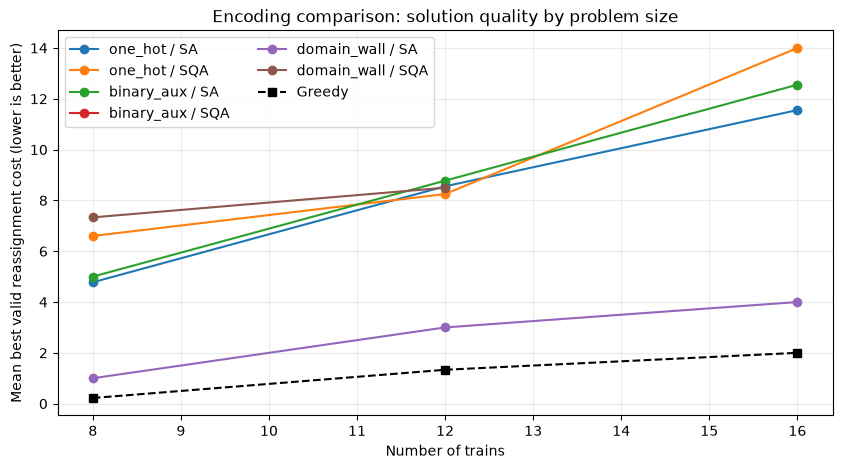

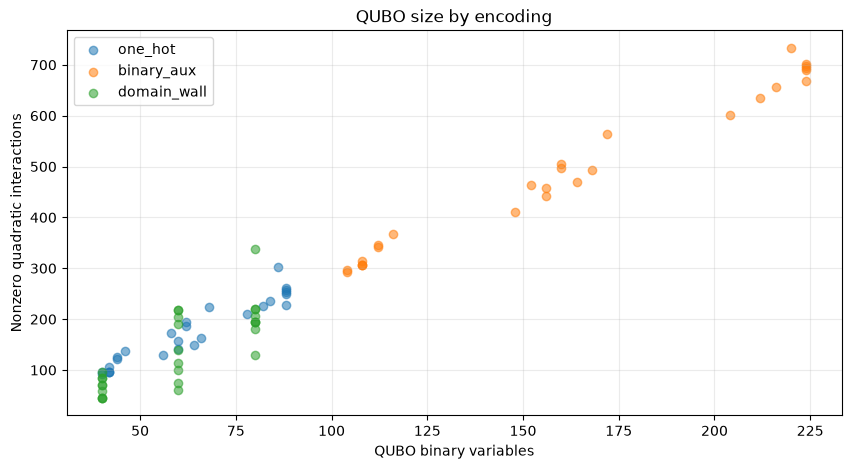

Single-bit neighbourhood diagnostics (not a full barrier proof):


,encoding,mean_variables_tested,mean_valid_single_bit_neighbours,median_min_one_bit_delta,mean_best_valid_move_cost_delta
0,binary_aux,162.518519,0.000000,13.0,NaN
1,domain_wall,60.000000,14.814815,0.0,0.481481
2,one_hot,63.259259,0.000000,12.0,NaN


In [13]:
if not sampler_runs.empty:
    dataset_encoding_summary=(sampler_runs.groupby(["dataset_id","n_trains","difficulty","encoding","algorithm"],dropna=False)
        .agg(repeats=("repeat","nunique"),mean_best_valid_cost=("best_valid_cost","mean"),
             best_cost_across_repeats=("best_valid_cost","min"),mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             median_runtime_s=("runtime_s","median"),successful_runs=("best_valid_cost",lambda x:int(x.notna().sum())))
        .reset_index().merge(dataset_diagnostics[["dataset_id","greedy_cost","exact_status","exact_cost"]],on="dataset_id",how="left"))
    dataset_encoding_summary["gap_to_exact"] = np.where(
        dataset_encoding_summary.exact_status=="OPTIMAL",
        dataset_encoding_summary.best_cost_across_repeats-dataset_encoding_summary.exact_cost,np.nan)
    encoding_summary=(dataset_encoding_summary.groupby(["encoding","algorithm","n_trains"],dropna=False)
        .agg(datasets=("dataset_id","nunique"),mean_best_valid_cost=("best_cost_across_repeats","mean"),
             mean_feasibility_pct=("mean_raw_feasibility_pct","mean"),median_runtime_s=("median_runtime_s","median"),
             exact_gap_mean=("gap_to_exact","mean"),runs_with_valid_sample=("successful_runs","sum"))
        .reset_index())
    print("Summary by encoding, algorithm and train count:")
    display(encoding_summary)
    print("Exact solver status:")
    display(dataset_diagnostics.groupby(["n_trains","difficulty","exact_status"]).size().rename("datasets").reset_index())
    print("Encoding size and density:")
    display(qubo_model_metrics.groupby("encoding").agg(
        mean_variables=("n_variables","mean"),mean_quadratic_interactions=("n_quadratic_interactions","mean"),
        mean_interaction_density=("interaction_density","mean"),max_coefficient=("max_abs_coefficient","max")).reset_index())

    fig,ax=plt.subplots(figsize=(10,5))
    for enc in ENCODINGS:
        for alg in ALGORITHMS:
            d=encoding_summary[(encoding_summary.encoding==enc)&(encoding_summary.algorithm==alg)]
            ax.plot(d.n_trains,d.mean_best_valid_cost,marker="o",label=f"{enc} / {alg}")
    greedy_curve=dataset_diagnostics.groupby("n_trains").greedy_cost.mean()
    ax.plot(greedy_curve.index,greedy_curve.values,marker="s",linestyle="--",color="black",label="Greedy")
    ax.set_xlabel("Number of trains"); ax.set_ylabel("Mean best valid reassignment cost (lower is better)")
    ax.set_title("Encoding comparison: solution quality by problem size")
    ax.grid(alpha=.25); ax.legend(ncol=2); plt.show()

    fig,ax=plt.subplots(figsize=(10,5))
    for enc in ENCODINGS:
        d=qubo_model_metrics[qubo_model_metrics.encoding==enc].groupby("n_variables").size()
        ax.scatter(qubo_model_metrics[qubo_model_metrics.encoding==enc].n_variables,
                   qubo_model_metrics[qubo_model_metrics.encoding==enc].n_quadratic_interactions,
                   alpha=.55,label=enc)
    ax.set_xlabel("QUBO binary variables"); ax.set_ylabel("Nonzero quadratic interactions")
    ax.set_title("QUBO size by encoding"); ax.grid(alpha=.25); ax.legend(); plt.show()

    if not landscape_diagnostics.empty:
        print("Single-bit neighbourhood diagnostics (not a full barrier proof):")
        display(landscape_diagnostics.groupby("encoding").agg(
            mean_variables_tested=("variables_tested","mean"),
            mean_valid_single_bit_neighbours=("valid_single_bit_neighbours","mean"),
            median_min_one_bit_delta=("min_one_bit_delta","median"),
            mean_best_valid_move_cost_delta=("best_valid_move_cost_delta","mean")).reset_index())
else:
    dataset_encoding_summary=encoding_summary=pd.DataFrame()
    print("No sampler results available.")

## 13. Export all V7 outputs

The output folder contains the instance tables, conflict graph edges, model metrics, raw sampler runs, per-dataset summaries, one-bit neighbourhood diagnostics, mathematical validation results and experiment metadata.

In [14]:
OUTPUT_DIR=Path.cwd()/"railway_v7_outputs"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def export_frame(frame,name):
    if frame is None or frame.empty:
        print("Not exported (empty):",name)
        return
    path=OUTPUT_DIR/name
    frame.to_csv(path,index=False)
    print("Saved:",path)

export_frame(dataset_diagnostics,"railway_v7_dataset_diagnostics.csv")
export_frame(generated_train_tables,"railway_v7_generated_train_tables.csv")
export_frame(conflict_edge_tables,"railway_v7_conflict_edges.csv")
export_frame(qubo_model_metrics,"railway_v7_qubo_model_metrics.csv")
export_frame(sampler_runs,"railway_v7_sampler_runs.csv")
export_frame(dataset_encoding_summary,"railway_v7_dataset_encoding_summary.csv")
export_frame(encoding_summary,"railway_v7_encoding_summary.csv")
export_frame(landscape_diagnostics,"railway_v7_single_bit_neighbourhood.csv")
export_frame(encoding_identity_preview,"railway_v7_encoding_identity_preview.csv")
export_frame(exhaustive_encoding_results,"railway_v7_exhaustive_encoding_validation.csv")

metadata={
    "notebook_version":"v7_generalised_encoding_benchmark",
    "study_mode":STUDY_MODE,
    "python_version":sys.version.split()[0],
    "platform":platform.platform(),
    "cpu":platform.processor(),
    "ram_gb":RAM_GB,
    "openjij_version":OPENJIJ_VERSION,
    "n_platforms":N_PLATFORMS,
    "long_platform_count":LONG_PLATFORM_COUNT,
    "long_train_coach_threshold":LONG_TRAIN_COACH_THRESHOLD,
    "clearance_min_assumption":CLEARANCE_MIN,
    "train_counts":TRAIN_COUNTS,
    "difficulty_levels":DIFFICULTIES,
    "difficulty_config":DIFFICULTY_CONFIG,
    "dataset_seeds":DATASET_SEEDS,
    "dataset_count":len(dataset_diagnostics) if not dataset_diagnostics.empty else 0,
    "encodings":ENCODINGS,
    "algorithms":ALGORITHMS,
    "solver_repeats":SOLVER_REPEATS,
    "num_reads":NUM_READS,
    "num_sweeps":NUM_SWEEPS,
    "qubo_identity_preview_passed":bool(encoding_identity_preview.passed.all()),
    "tiny_exhaustive_passed":bool(exhaustive_encoding_results.ground_state_matches_categorical_optimum.all()) if not exhaustive_encoding_results.empty else None,
    "all_dataset_qubo_identity_passed":bool(qubo_model_metrics.identity_passed.all()) if not qubo_model_metrics.empty else None,
    "synthetic_data_notice":"All train-level schedules, delays, nominal platform assignments, coach counts and conflicts are synthetic; no station-specific dataset is used.",
    "quantum_notice":"OpenJij SQA is a classical simulation, not execution on quantum hardware.",
    "raw_feasibility_notice":"No repair decoder is applied in the primary benchmark; only internally consistent, conflict-free decoded samples count as raw feasible."
}
with open(OUTPUT_DIR/"railway_v7_experiment_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata,f,indent=2)
print("V7 output directory:",OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_qubo_model_metrics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_dataset_encoding_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_encoding_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_single_bit_neighbourhood.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_encoding_identity_preview.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v7_outputs\railway_v7_exhaustive_encoding_v

## 14. Interpretation checklist and stop/go decision

Before selecting an encoding for V8, check all of the following:

- [ ] Random-assignment energy identity checks pass for all three encodings.
- [ ] Exhaustive tiny-instance ground-state validation passes for all three encodings.
- [ ] Per-dataset QUBO checks pass for every encoding.
- [ ] Raw sampler feasibility is reported separately from objective quality.
- [ ] Greedy and Exact Search use the same generated datasets as SA/SQA.
- [ ] Exact `TIMEOUT` cases are not described as optimal or infeasible.
- [ ] Variable count, interaction count, density and coefficient scale are reported.
- [ ] One-bit neighbourhood results are described only as local-move diagnostics, not as a complete proof of the annealing landscape.
- [ ] The best encoding is selected on calibration evidence and then frozen before V8's final held-out benchmark.

### Important interpretation

Binary encoding may reduce the number of state bits but require many AND/indicator auxiliaries. Domain-wall encoding uses fewer state bits and supports adjacent categorical moves through single-bit flips, but its conservative wall-penalty bound may create large coefficients. One-hot may remain the most compact QUBO after all auxiliary variables are counted. The experiment is designed to measure these trade-offs; it does not presume a winner.

If one or more encodings fail the exhaustive test, do not run or interpret their sampler results until the formulation is corrected.